<div style="padding:20px; border-radius:6px; background-color:#ffe6e6; color:#b30000; border-left:5px solid #b30000;">
<b>To be able to run this notebook, choose environment <code>mandala_env</code></b>
</div>

In [1]:
import os
import yaml
import pandas as pd
import datetime
import mandala
import fsspec
import xarray as xr
import zcollection as zc
import zcollection.fs_utils as zc_fs
from typing import Literal

from training_ofs import load_s3_options_from_vault

## Introduction

Marine Data Lake (Mandala) stores MMS1 observational and numerical model datasets in object storage. These datasets can be accessed through the S3 protocol.

### s3 configurations

In [ ]:
# Paste your Vault token here for local runs.
VAULT_TOKEN = ""

s3_options = load_s3_options_from_vault(token=VAULT_TOKEN)

fs = fsspec.filesystem(
    's3',
    key=s3_options['key'],
    secret=s3_options['secret'],
    client_kwargs=s3_options['client_kwargs'],
)
fs


#### Get catalog

In [19]:
def get_catalog(database: Literal['obs','model', 'model_hindcast'], s3_options: dict):
    catalog = {"obs": "catalog.json", "model": "catalog.json", "model_hindcast": "catalog_hindcast.json"}.get(database, "catalog.json")
    if database == 'model_hindcast':
        database = 'model'
    catalog_path = os.path.join('mandala-prod1/datalake/', database, catalog)
    return mandala.MandalaCatalog(path = catalog_path,
                          protocol="s3",
                          options = s3_options)

In [20]:
# observation
catalogobs = get_catalog('obs', s3_options)
catalogobs

Path,Product type,First date,Last date,Update
mandala-prod1/datalake/obs/collections/arvor_c,ARVOR_C,2022-02-24T00:00:00,2026-10-22T03:07:00,2026-10-22T03:32:25
mandala-prod1/datalake/obs/collections/arvor_i,ARVOR_I,2022-02-25T08:29:21,2026-10-23T13:04:03,2026-10-23T13:11:39
mandala-prod1/datalake/obs/collections/svp,SVP,2022-02-22T08:00:00,2026-11-02T12:06:00,2026-10-23T23:17:25
mandala-prod1/datalake/obs/collections/vaws,VAWS,2000-01-01T01:00:00,2068-08-12T03:40:00,2026-10-24T17:16:04
mandala-prod1/datalake/obs/collections/maws,MAWS,2022-04-25T09:40:00,2026-10-23T23:10:00,2026-10-24T17:15:06
mandala-prod1/datalake/grid/collections/radar/bada,RADAR_TOTAL_BADA,1971-12-31T20:51:24,2026-10-23T22:30:00,2026-10-24T17:16:11
mandala-prod1/datalake/grid/collections/radar/sega,RADAR_TOTAL_SEGA,1973-02-07T11:11:24,2026-10-23T22:30:00,2026-10-24T17:16:19


In [21]:
# model
catalogmodel = get_catalog('model', s3_options)
catalogmodel

Path,Product type,First date,Last date,Update
mandala-prod1/datalake/model/collections/inacawo_ocean_2d,INACAWO_OCEAN_2D,2024-01-18T12:00:00,2026-11-05T12:00:00,2026-10-27T07:13:59
mandala-prod1/datalake/model/collections/inacawo_wrf_2d,INACAWO_WRF_2D,2024-01-18T12:00:00,2026-11-05T12:00:00,2026-10-27T07:15:23
mandala-prod1/datalake/model/collections/inacawo_ocean_3d,INACAWO_OCEAN_3D,2024-01-18T12:00:00,2026-11-05T12:00:00,2026-10-27T07:27:50
mandala-prod1/datalake/model/collections/inacawo_wrf_3d,INACAWO_WRF_3D,2024-01-18T12:00:00,2026-11-05T12:00:00,2026-10-27T07:54:25
mandala-prod1/datalake/model/collections/inawaves,INAWAVES,2024-10-17T12:00:00,2026-09-22T09:00:00,2026-09-07T00:20:55
mandala-prod1/datalake/model/collections/inaflows,INAFLOWS,2024-10-18T00:00:00,2026-09-15T21:00:00,2026-09-06T21:20:38
mandala-prod1/datalake/model/collections/inacawo_realtime_ocean_2d,INACAWO_REALTIME_OCEAN_2D,2026-10-26T00:00:00,2026-10-28T20:00:00,2026-10-27T07:13:17
mandala-prod1/datalake/model/collections/inacawo_realtime_wrf_2d,INACAWO_REALTIME_WRF_2D,2026-10-26T00:00:00,2026-10-28T12:00:00,2026-10-27T07:14:47
mandala-prod1/datalake/model/collections/inacawo_realtime_ocean_3d,INACAWO_REALTIME_OCEAN_3D,2026-10-26T00:00:00,2026-10-28T19:00:00,2026-10-27T07:23:48
mandala-prod1/datalake/model/collections/inacawo_realtime_wrf_3d,INACAWO_REALTIME_WRF_3D,2026-10-26T00:00:00,2026-10-28T11:00:00,2026-10-27T07:46:21


In [22]:
# model
catalogmodelhindcast = get_catalog('model_hindcast', s3_options)
catalogmodelhindcast

Path,Product type,First date,Last date,Update
mandala-prod1/datalake/model/collections/inacawo_hindcast_ocean_2d,INACAWO_HINDCAST_OCEAN_2D,1995-01-01T12:00:00,2015-02-01T12:00:00,2026-08-10T05:21:13
mandala-prod1/datalake/model/collections/inacawo_hindcast_wrf_2d,INACAWO_HINDCAST_WRF_2D,1995-01-01T15:00:00,2015-02-01T12:00:00,2026-09-07T02:34:59
mandala-prod1/datalake/model/collections/inacawo_hindcast_wrf_3d,INACAWO_HINDCAST_WRF_3D,1995-01-01T15:00:00,2015-02-01T12:00:00,2026-10-09T01:31:44
mandala-prod1/datalake/model/collections/inacawo_hindcast_ocean_3d,INACAWO_HINDCAST_OCEAN_3D,1995-01-01T12:00:00,2015-02-01T12:00:00,2026-10-09T04:22:36


#### Processing datasets

All datasets are stores in `zcollection` format, which is built on top of the `zarr` format. Therefore, they can be efficiently processed using `xarray`.

Here is an example processing dataset `inacawo_ocean_2d`. Other datasets can be accessed and processed in the same way by changing the dataset path.

In [25]:
fs.invalidate_cache() 
ocean2d_collection = zc.open_collection(
    path="mandala-prod1/datalake/model/collections/inacawo_ocean_2d", 
    mode="r", 
    filesystem=zc_fs.get_fs(filesystem=fs)
)

date_filter = (
    "(year == 2026 and month == 9 and day >= 12) or "
    "(year == 2026 and month == 9 and day <= 13)"
)

dset = ocean2d_collection.load(delayed=True, filters=date_filter).to_xarray()
dset

<xarray.Dataset>
Dimensions:           (TSTEP: 720, LAY: 1, ROW: 1201, COL: 2201)
Coordinates:
  * TSTEP             (TSTEP) datetime64[ns] 2026-09-01 ... 2026-09-30T23:00:00
  * ROW               (ROW) float64 -15.0 -14.97 -14.95 ... 14.95 14.98 15.0
  * COL               (COL) float64 90.0 90.02 90.05 90.08 ... 144.9 145.0 145.0
Dimensions without coordinates: LAY
Data variables: (12/29)
    swrad             (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    zeta              (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    ubar_eastward     (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    salt_sur          (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    wind_sea_perd     (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    sig_wave_height   (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    ...                ...
    prim_swell_wlen   (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    net_salt_flux     (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    wind_sea_dir      (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    lon               (COL) float32 dask.array<chunksize=(1101,), meta=np.ndarray>
    lat               (ROW) float32 dask.array<chunksize=(601,), meta=np.ndarray>
    geographic        |S1 dask.array<chunksize=(), meta=np.ndarray>

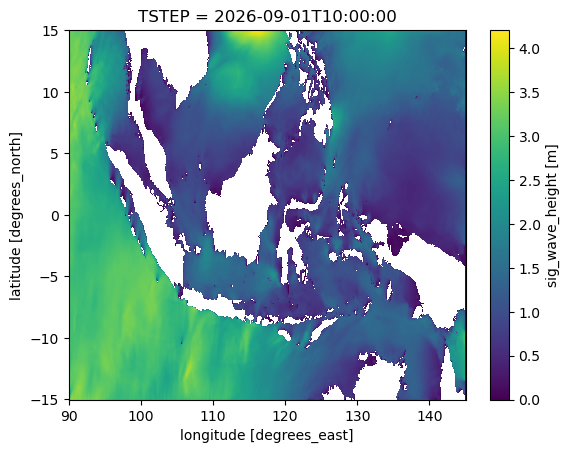

In [26]:
# quick plot 

dset.isel(TSTEP=10).sig_wave_height.plot()